# Fila Digital — Data Science com dados reais (GS CitizenTech 2026.2)

**Problema:** quem precisa de atendimento de urgência na rede pública não sabe quanto vai esperar em cada unidade, e as unidades ficam desequilibradas.

**Território:** Prontos-Atendimentos de **Barueri/SP**. As unidades levam o nome do bairro (Engenho Novo, Imperial, Camargo, Mutinga) ou da especialidade (PAA = adulto, PAI = infantil).

**Fontes (públicas e agregadas, sem dado pessoal):**
1. *Histórico:* capturas do painel da Prefeitura guardadas no **Internet Archive (Wayback Machine)**, 2017–2026 (`dados/historico_wayback.csv`, gerado por `baixar_historico_wayback.py`).
2. *Ao vivo:* coleta contínua do mesmo painel a cada 5 min (`dados/espera_barueri_ao_vivo.csv`, gerado por `coletar_barueri.py` e pelo app Fila Certa).
   - Painel: https://saudeservicos.barueri.sp.gov.br/AgendamentoOnline/TempoAtendimentoPS.aspx

**Perguntas:**
- *P1 (descritiva):* quanto se espera, e como isso varia por unidade, setor, horário e dia da semana?
- *P2 (preditiva, perfil):* dado unidade, setor e horário, qual a espera típica e qual a chance de ela passar de 20 min? (regressão linear e logística)
- *P3 (preditiva, curto prazo):* dado o estado atual das filas, qual a espera daqui a 15 min? (exige série de leituras seguidas; ver seção 6)

In [1]:
import re, json, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
                             precision_score, recall_score, f1_score, confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

PASTA = Path("dados"); FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
LIMIAR_LONGA = 20        # minutos: acima disso a espera e considerada "longa"
HORIZONTE_MIN = 15       # horizonte da previsao de curto prazo
FUSO_HORAS = 3           # o Archive grava a hora em UTC; o painel mostra a hora local (UTC-3)
ESPERA_MAX_VALIDA = 600  # 10 h: acima disso a leitura e erro do painel
DEFASAGEM_MAX_H = 2      # leitura com mais de 2 h de atraso em relacao a captura = painel parado

## 1. Carga e unificação

O formato é o mesmo do notebook original do grupo (`local, tempo_espera, ts`), com a coluna `captura` (instante em que a leitura foi obtida) para podermos detectar painel parado.

In [2]:
hist = pd.read_csv(PASTA / "historico_wayback.csv", parse_dates=["ts", "captura"])
hist["origem"] = "historico"
hist["captura_local"] = hist["captura"] - pd.Timedelta(hours=FUSO_HORAS)   # UTC -> hora local

arq_vivo = PASTA / "espera_barueri_ao_vivo.csv"
vivo = pd.read_csv(arq_vivo, parse_dates=["ts", "coletado_em"]) if arq_vivo.exists() else pd.DataFrame()
if len(vivo):
    vivo["origem"] = "ao_vivo"
    vivo["captura_local"] = vivo["coletado_em"]                              # ja esta na hora local
    vivo["captura"] = vivo["coletado_em"]

COLS = ["local", "tempo_espera", "ts", "captura_local", "origem"]
bruto = pd.concat([hist[COLS], vivo[COLS] if len(vivo) else None], ignore_index=True)
print(f"historico: {len(hist):,} leituras | ao vivo: {len(vivo):,} leituras | total bruto: {len(bruto):,}")
print("periodo:", bruto['ts'].min(), "ate", bruto['ts'].max())
bruto.head()

historico: 1,532 leituras | ao vivo: 144 leituras | total bruto: 1,676
periodo: 2017-10-21 17:26:20 ate 2026-11-17 22:35:00


,local,tempo_espera,ts,captura_local,origem
0,PEDIATRIA - PRONTO SOCORRO CENTRAL INFANTIL,165.0,2017-10-21 17:26:20,2018-02-13 01:57:45,historico
1,CLINICO GERAL - PRONTO SOCORRO CENTRAL,80.0,2017-11-06 10:31:18,2018-02-13 01:57:45,historico
2,ORTOPEDIA - PRONTO SOCORRO CENTRAL,25.0,2017-11-06 10:31:25,2018-02-13 01:57:45,historico
3,CLINICO GERAL - PRONTO SOCORRO IMPERIAL,60.0,2018-01-07 15:19:07,2018-02-13 01:57:45,historico
4,ORTOPEDIA - PRONTO SOCORRO IMPERIAL,20.0,2018-01-07 15:19:12,2018-02-13 01:57:45,historico


## 2. Tratamento dos dados

Problemas encontrados ao inspecionar os dados reais, e o que foi feito:

| Problema | Evidência | Tratamento |
|---|---|---|
| Texto de tempo com horas (`"1 h e 36 min"`) | o notebook original lia só o primeiro número (1 min) | conversão correta para minutos (96) |
| Valor impossível | espera de **2.400 min** (40 h) | descartar `>= 600 min` |
| Painel parado (leitura velha) | `ts` muito anterior à captura (até 114 dias) | descartar defasagem `> 2 h` |
| Nomes diferentes ao longo dos anos | `PS CAMARGO` × `PARQUE DOS CAMARGOS`, espaços duplos | normalizar texto; extrair **unidade** e **setor** |
| Fuso | captura (UTC) 3 h à frente de `ts` (hora local) | converter a captura para hora local |
| Duplicatas | mesma leitura em capturas repetidas | `drop_duplicates(local, ts)` |

In [3]:
def _norm(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()

def extrair_unidade(local):
    n = _norm(local)
    for chave in ["ENGENHO NOVO", "IMPERIAL", "CAMARGO", "MUTINGA", "HMB"]:
        if chave in n:
            return chave
    if re.search(r"\bPAA\b", n): return "PAA"
    if re.search(r"\bPAI\b", n): return "PAI"
    return "OUTRA"

def extrair_setor(local):
    n = _norm(local).replace("PRONTO ATENDIMENTO", "").replace("PRONTO SOCORRO", "")
    for chave in ["TRIAGEM", "EMERGENCIA", "ORTOPEDIA", "PEDIATRIA", "GINECOLOGIA", "ODONTOLOGIA", "CLINICO"]:
        if chave in n:
            return chave
    return "ATENDIMENTO" if "ATENDIMENTO" in n else "OUTRO"

df = bruto.copy()
df["local"] = df["local"].str.replace(r"\s+", " ", regex=True).str.strip()
df["defasagem_h"] = (df["captura_local"] - df["ts"]).dt.total_seconds() / 3600

registro = [("leituras brutas", len(df))]
n0 = len(df); df = df.dropna(subset=["tempo_espera", "ts"]);                        registro.append(("sem valor ou sem data", n0 - len(df)))
n0 = len(df); df = df[df["tempo_espera"] < ESPERA_MAX_VALIDA];                      registro.append((f"espera >= {ESPERA_MAX_VALIDA} min (erro)", n0 - len(df)))
n0 = len(df); df = df[df["defasagem_h"] <= DEFASAGEM_MAX_H];                        registro.append((f"painel parado (defasagem > {DEFASAGEM_MAX_H} h)", n0 - len(df)))
n0 = len(df); df = df.drop_duplicates(["local", "ts"]);                             registro.append(("duplicadas", n0 - len(df)))
df["unidade"] = df["local"].map(extrair_unidade)
df["setor"] = df["local"].map(extrair_setor)
df["sintomas"] = df["local"].map(lambda s: int(bool(re.search("SINTOMAS|SUSPEITA", _norm(s)))))
df = df.sort_values("ts").reset_index(drop=True)
registro.append(("leituras finais", len(df)))
print(pd.DataFrame(registro, columns=["etapa", "linhas"]).to_string(index=False))

# variaveis de tempo
h = df["ts"].dt.hour + df["ts"].dt.minute / 60
df["hora"] = df["ts"].dt.hour
df["dia_semana"] = df["ts"].dt.dayofweek
df["fim_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df["ano"] = df["ts"].dt.year
df["hora_sen"] = np.sin(2 * np.pi * h / 24); df["hora_cos"] = np.cos(2 * np.pi * h / 24)
df["espera_longa"] = (df["tempo_espera"] >= LIMIAR_LONGA).astype(int)
print("\nunidades:", df["unidade"].value_counts().to_dict())
print("setores :", df["setor"].value_counts().to_dict())
print("sem classificacao (OUTRA/OUTRO):", int(((df.unidade == 'OUTRA') | (df.setor == 'OUTRO')).sum()))

                          etapa  linhas
                leituras brutas    1676
          sem valor ou sem data       0
       espera >= 600 min (erro)       1
painel parado (defasagem > 2 h)      77
                     duplicadas       0
                leituras finais    1598

unidades: {'IMPERIAL': 382, 'ENGENHO NOVO': 310, 'CAMARGO': 281, 'PAA': 252, 'PAI': 209, 'MUTINGA': 143, 'OUTRA': 14, 'HMB': 7}
setores : {'CLINICO': 318, 'PEDIATRIA': 314, 'TRIAGEM': 291, 'ATENDIMENTO': 278, 'ORTOPEDIA': 148, 'GINECOLOGIA': 85, 'EMERGENCIA': 81, 'ODONTOLOGIA': 63, 'OUTRO': 20}
sem classificacao (OUTRA/OUTRO): 34


## 3. Análise exploratória (P1)

Tamanho da amostra e **vieses** primeiro: as capturas do Archive não são sorteadas, então alguns horários aparecem muito mais que outros. Isso limita as conclusões sobre horário.

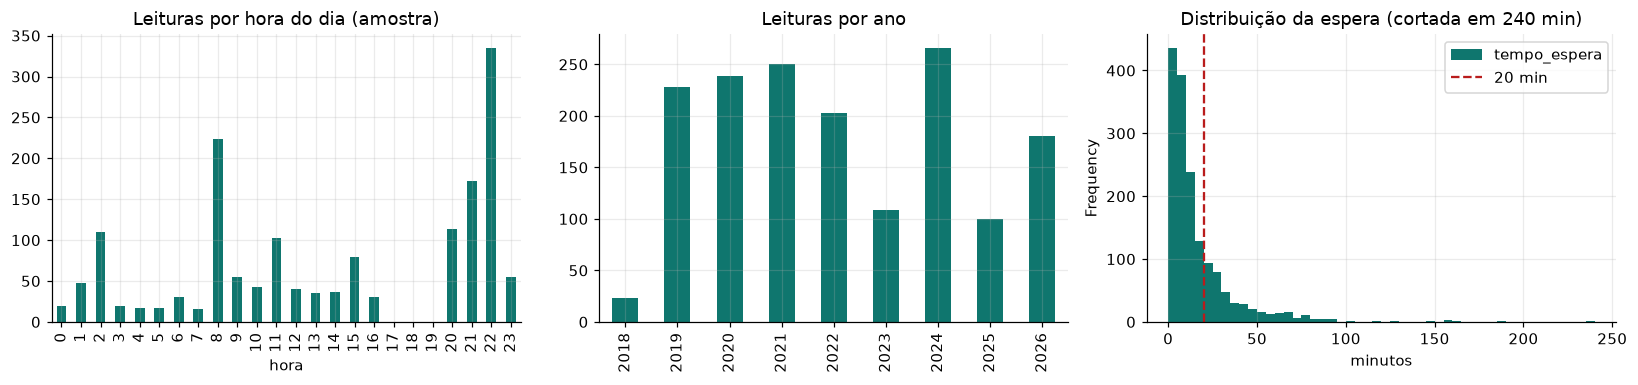

count    1598.0
mean       16.0
std        20.6
min         0.0
25%         4.0
50%         9.0
75%        20.0
max       244.0

assimetria = 3.7 (cauda longa: a mediana descreve melhor que a media)
espera longa (>= 20 min): 25.1% das leituras


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
df.groupby("hora").size().reindex(range(24), fill_value=0).plot.bar(ax=ax[0], color="#0f766e"); ax[0].set_title("Leituras por hora do dia (amostra)"); ax[0].set_xlabel("hora")
df.groupby("ano").size().plot.bar(ax=ax[1], color="#0f766e"); ax[1].set_title("Leituras por ano"); ax[1].set_xlabel("")
df["tempo_espera"].clip(upper=240).plot.hist(bins=48, ax=ax[2], color="#0f766e"); ax[2].axvline(LIMIAR_LONGA, color="#b91c1c", ls="--", label=f"{LIMIAR_LONGA} min"); ax[2].legend()
ax[2].set_title("Distribuição da espera (cortada em 240 min)"); ax[2].set_xlabel("minutos")
plt.tight_layout(); plt.savefig(FIG / "01_amostra_e_distribuicao.png"); plt.show()
print(df["tempo_espera"].describe().round(1).to_string())
print(f"\nassimetria = {stats.skew(df['tempo_espera']):.1f} (cauda longa: a mediana descreve melhor que a media)")
print(f"espera longa (>= {LIMIAR_LONGA} min): {df['espera_longa'].mean():.1%} das leituras")

POR UNIDADE (bairro)
                n  mediana   p75   p90  pct_longa
unidade                                          
CAMARGO       281     11.0  25.0  57.0       28.5
PAA           252     11.0  24.0  49.6       32.5
ENGENHO NOVO  310     10.0  17.8  30.1       22.3
IMPERIAL      382      9.0  17.0  32.0       22.3
PAI           209      9.0  21.0  38.2       27.8
MUTINGA       143      5.0  13.5  31.8       17.5
OUTRA          14      3.0   8.8  12.4        7.1
HMB             7      1.0   1.5   9.2       14.3

POR SETOR
               n  mediana   p75   p90  pct_longa
setor                                           
CLINICO      318     22.0  44.0  68.3       57.5
OUTRO         20     22.0  41.2  77.1       65.0
ORTOPEDIA    148     13.0  21.5  34.3       29.7
PEDIATRIA    314     12.0  21.8  34.7       27.1
ODONTOLOGIA   63     11.0  22.5  32.4       31.7
EMERGENCIA    81     10.0  22.0  32.0       25.9
GINECOLOGIA   85      9.0  18.0  39.0       20.0
TRIAGEM      291      6.0  

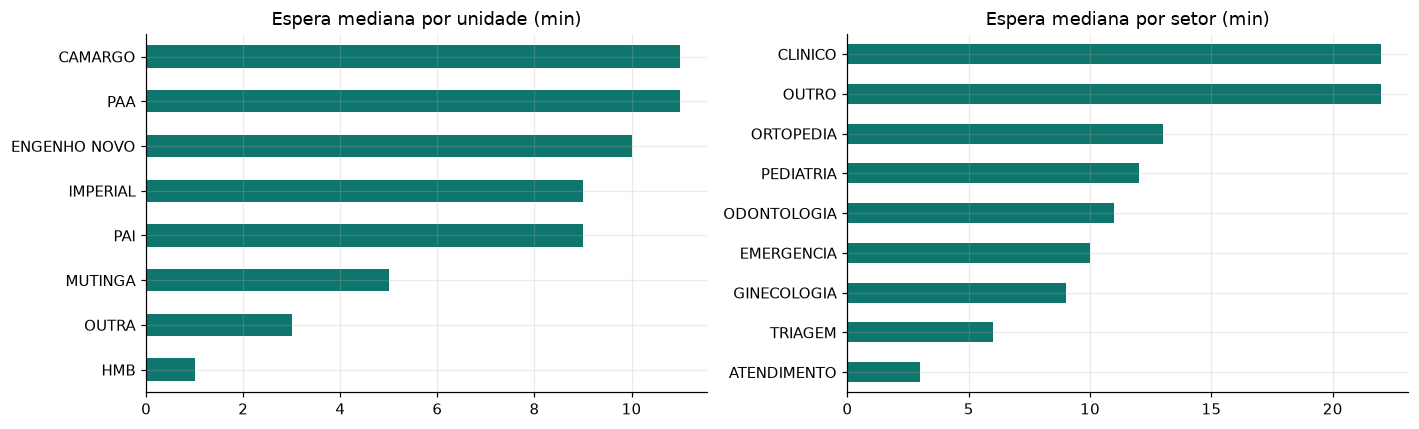

In [5]:
def resumo(col):
    t = df.groupby(col)["tempo_espera"].agg(n="count", mediana="median", p75=lambda s: s.quantile(.75), p90=lambda s: s.quantile(.9), pct_longa=lambda s: (s >= LIMIAR_LONGA).mean() * 100)
    return t.round(1).sort_values("mediana", ascending=False)

por_unidade, por_setor = resumo("unidade"), resumo("setor")
print("POR UNIDADE (bairro)"); print(por_unidade.to_string())
print("\nPOR SETOR"); print(por_setor.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_unidade["mediana"][::-1].plot.barh(ax=ax[0], color="#0f766e"); ax[0].set_title("Espera mediana por unidade (min)")
por_setor["mediana"][::-1].plot.barh(ax=ax[1], color="#0f766e"); ax[1].set_title("Espera mediana por setor (min)")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "02_por_unidade_e_setor.png"); plt.show()

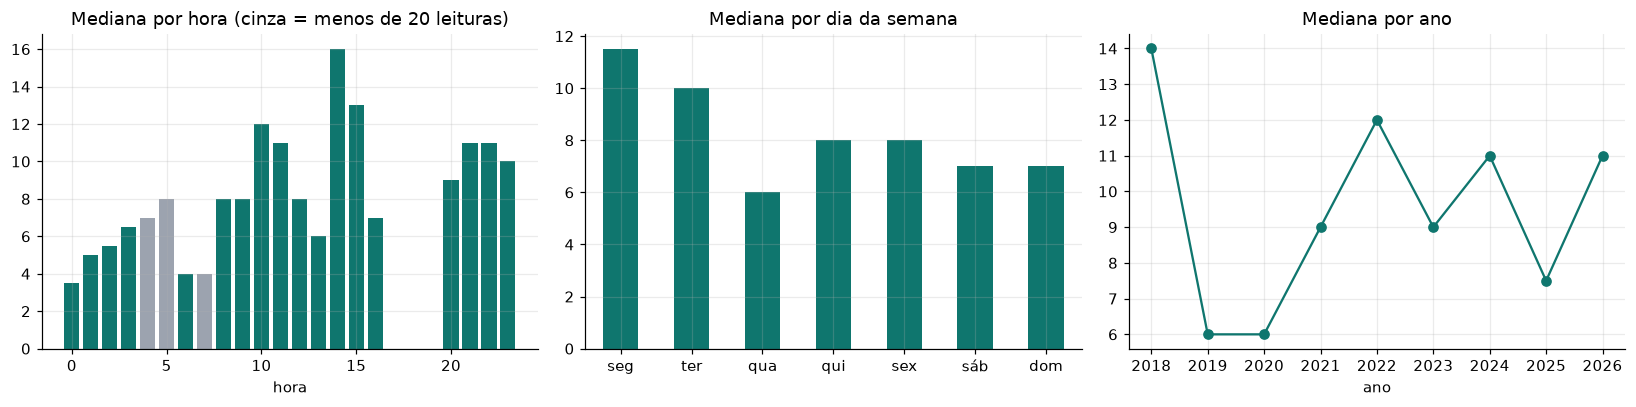

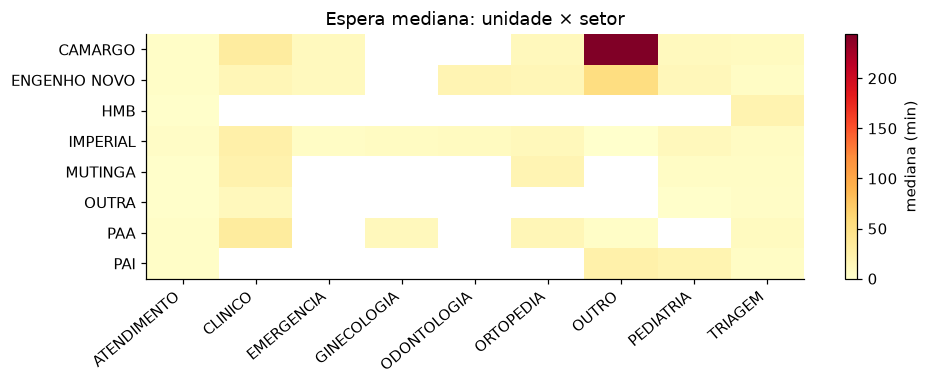

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
t = df.groupby("hora")["tempo_espera"].agg(["median", "count"]).reindex(range(24))
ax[0].bar(t.index, t["median"], color=np.where(t["count"] >= 20, "#0f766e", "#9ca3af")); ax[0].set_title("Mediana por hora (cinza = menos de 20 leituras)"); ax[0].set_xlabel("hora")
d = df.groupby("dia_semana")["tempo_espera"].median().reindex(range(7)); d.index = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
d.plot.bar(ax=ax[1], color="#0f766e", rot=0); ax[1].set_title("Mediana por dia da semana")
df.groupby("ano")["tempo_espera"].median().plot(ax=ax[2], marker="o", color="#0f766e"); ax[2].set_title("Mediana por ano")
plt.tight_layout(); plt.savefig(FIG / "03_por_hora_dia_ano.png"); plt.show()

pivo = df.pivot_table(index="unidade", columns="setor", values="tempo_espera", aggfunc="median")
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(pivo.values, aspect="auto", cmap="YlOrRd"); ax.set_xticks(range(len(pivo.columns))); ax.set_xticklabels(pivo.columns, rotation=40, ha="right")
ax.set_yticks(range(len(pivo.index))); ax.set_yticklabels(pivo.index); ax.grid(False); plt.colorbar(im, label="mediana (min)")
ax.set_title("Espera mediana: unidade × setor"); plt.tight_layout(); plt.savefig(FIG / "04_mapa_unidade_setor.png"); plt.show()

## 4. Testes estatísticos

Como a espera tem cauda longa, usamos testes **não paramétricos**. `ε²` é o tamanho do efeito do Kruskal–Wallis (0,01 pequeno · 0,06 médio · 0,14 grande).

In [7]:
def kruskal(col):
    grupos = [g["tempo_espera"].values for _, g in df.groupby(col) if len(g) >= 5]
    H, p = stats.kruskal(*grupos); k, n = len(grupos), sum(len(g) for g in grupos)
    return H, p, (H - k + 1) / (n - k)

resultados = []
for col, nome in [("unidade", "unidade"), ("setor", "setor"), ("hora", "hora do dia"), ("dia_semana", "dia da semana"), ("ano", "ano")]:
    H, p, e2 = kruskal(col); resultados.append((f"A espera difere por {nome}?", f"H={H:.1f}", f"p={p:.2g}", f"ε²={e2:.3f}", "sim" if p < .05 else "não"))
u, p = stats.mannwhitneyu(df.loc[df.fim_de_semana == 1, "tempo_espera"], df.loc[df.fim_de_semana == 0, "tempo_espera"])
resultados.append(("Fim de semana x dia útil?", f"U={u:.0f}", f"p={p:.2g}", "", "sim" if p < .05 else "não"))
print(pd.DataFrame(resultados, columns=["pergunta", "estatística", "p-valor", "efeito", "significativo (5%)"]).to_string(index=False))
print("\nLeitura: p-valor baixo = a diferença observada dificilmente seria acaso; ε² mostra se ela e grande ou pequena na pratica.")

                          pergunta estatística    p-valor   efeito significativo (5%)
      A espera difere por unidade?      H=44.0  p=2.1e-07 ε²=0.023                sim
        A espera difere por setor?     H=552.5 p=3.7e-114 ε²=0.343                sim
  A espera difere por hora do dia?     H=130.3  p=3.4e-18 ε²=0.070                sim
A espera difere por dia da semana?      H=31.4  p=2.1e-05 ε²=0.016                sim
          A espera difere por ano?      H=56.2  p=2.6e-09 ε²=0.030                sim
         Fim de semana x dia útil?    U=206779   p=0.0028                         sim

Leitura: p-valor baixo = a diferença observada dificilmente seria acaso; ε² mostra se ela e grande ou pequena na pratica.


## 5. Modelos com dados reais — P2: perfil de espera

Regressão **linear** (espera esperada em minutos) e **logística** (probabilidade de espera ≥ 20 min), usando só o que se sabe *antes*: unidade, setor, sintomas, hora e fim de semana.

**Sem vazamento:** a divisão é **temporal** (treino = leituras mais antigas, teste = as mais recentes), e o padronizador/one-hot é ajustado só no treino. **Baselines:** mediana do setor (regressão) e "sempre a classe mais comum" (logística).

In [8]:
NUM = ["hora_sen", "hora_cos", "fim_de_semana", "sintomas"]
CAT = ["unidade", "setor"]
dfm = df[(df.unidade != "OUTRA") & (df.setor != "OUTRO")].copy()

corte = dfm["ts"].quantile(0.75)
treino, teste = dfm[dfm.ts <= corte], dfm[dfm.ts > corte]
print(f"corte temporal em {corte:%d/%m/%Y} | treino: {len(treino)} leituras ({treino.ts.min():%Y}–{treino.ts.max():%Y}) | teste: {len(teste)} ({teste.ts.min():%Y}–{teste.ts.max():%Y})")
print(f"espera longa — treino: {treino.espera_longa.mean():.1%} | teste: {teste.espera_longa.mean():.1%}")

def pre():
    return ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

# --- regressao linear (alvo cortado no p99 do treino para a cauda nao dominar o ajuste)
TETO = float(treino["tempo_espera"].quantile(0.99))
reg = Pipeline([("pre", pre()), ("m", LinearRegression())]).fit(treino[NUM + CAT], treino["tempo_espera"].clip(upper=TETO))
pred = np.clip(reg.predict(teste[NUM + CAT]), 0, None)
base_setor = treino.groupby("setor")["tempo_espera"].median()
pred_base = teste["setor"].map(base_setor).fillna(treino["tempo_espera"].median())
y = teste["tempo_espera"]
met_reg = {"MAE (min)": [mean_absolute_error(y, pred), mean_absolute_error(y, pred_base)],
           "RMSE (min)": [np.sqrt(mean_squared_error(y, pred)), np.sqrt(mean_squared_error(y, pred_base))],
           "R²": [r2_score(y, pred), r2_score(y, pred_base)]}
print("\nREGRESSAO LINEAR (teste)"); print(pd.DataFrame(met_reg, index=["modelo", "baseline (mediana do setor)"]).T.round(2).to_string())

nomes = reg.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(reg.named_steps["m"].coef_, index=nomes).sort_values(key=abs, ascending=False)
print("\nmaiores coeficientes (variaveis padronizadas):"); print(coefs.head(8).round(2).to_string())

corte temporal em 07/09/2024 | treino: 1184 leituras (2018–2024) | teste: 380 (2024–2026)
espera longa — treino: 23.5% | teste: 28.7%

REGRESSAO LINEAR (teste)
            modelo  baseline (mediana do setor)
MAE (min)    10.34                        10.57
RMSE (min)   16.49                        18.77
R²            0.31                         0.11

maiores coeficientes (variaveis padronizadas):
cat__setor_CLINICO        14.22
cat__setor_ATENDIMENTO   -10.42
cat__unidade_MUTINGA      -7.36
cat__setor_TRIAGEM        -7.27
cat__setor_GINECOLOGIA    -4.41
cat__setor_ODONTOLOGIA     4.26
cat__unidade_PAI           3.98
cat__unidade_PAA           3.93


REGRESSAO LOGISTICA (teste)
          modelo  baseline (aleatório)
ROC AUC    0.844                   0.5
precisão   0.500                   NaN
recall     0.844                   NaN
F1         0.628                   NaN

matriz de confusao (linhas = real, colunas = previsto):
 [[179  92]
 [ 17  92]]

razoes de chance (odds ratio) — maiores:
cat__setor_CLINICO        6.31
cat__unidade_HMB          2.84
cat__setor_ODONTOLOGIA    2.72
cat__unidade_PAI          2.01
cat__setor_ORTOPEDIA      1.98
cat__setor_EMERGENCIA     1.95


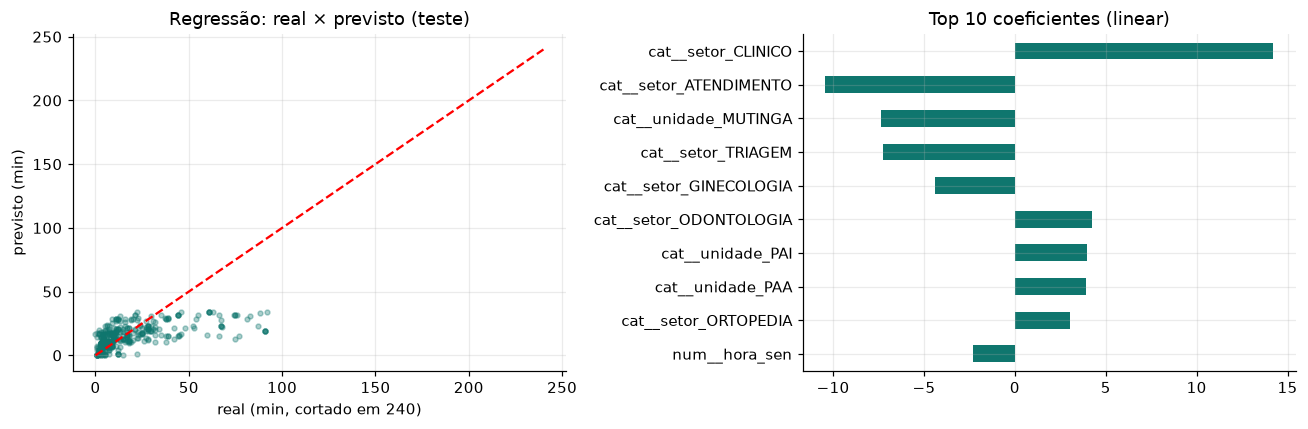

In [9]:
# --- regressao logistica: P(espera >= 20 min)
clf = Pipeline([("pre", pre()), ("m", LogisticRegression(max_iter=3000, class_weight="balanced"))]).fit(treino[NUM + CAT], treino["espera_longa"])
proba = clf.predict_proba(teste[NUM + CAT])[:, 1]; pc = (proba >= 0.5).astype(int); yc = teste["espera_longa"]
prop_base = treino["espera_longa"].mean()
met_clf = {"ROC AUC": [roc_auc_score(yc, proba), 0.5], "precisão": [precision_score(yc, pc, zero_division=0), np.nan],
           "recall": [recall_score(yc, pc, zero_division=0), np.nan], "F1": [f1_score(yc, pc, zero_division=0), np.nan]}
print("REGRESSAO LOGISTICA (teste)"); print(pd.DataFrame(met_clf, index=["modelo", "baseline (aleatório)"]).T.round(3).to_string())
print("\nmatriz de confusao (linhas = real, colunas = previsto):\n", confusion_matrix(yc, pc))

odds = pd.Series(np.exp(clf.named_steps["m"].coef_[0]), index=clf.named_steps["pre"].get_feature_names_out()).sort_values(ascending=False)
print("\nrazoes de chance (odds ratio) — maiores:"); print(odds.head(6).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y.clip(upper=240), pred, s=10, alpha=.35, color="#0f766e"); ax[0].plot([0, 240], [0, 240], "r--"); ax[0].set_xlabel("real (min, cortado em 240)"); ax[0].set_ylabel("previsto (min)"); ax[0].set_title("Regressão: real × previsto (teste)")
coefs.head(10)[::-1].plot.barh(ax=ax[1], color="#0f766e"); ax[1].set_title("Top 10 coeficientes (linear)")
plt.tight_layout(); plt.savefig(FIG / "05_modelo_perfil.png"); plt.show()

## 6. Previsão de curto prazo (P3) — depende da coleta ao vivo

A pergunta original do grupo — *"qual a espera daqui a 15 min?"* — precisa de leituras **seguidas** (de 5 em 5 min) para medir a tendência (`espera_atual` × `espera_15min_atrás`). O histórico do Archive é espaçado demais para isso, então este modelo só pode ser treinado com a **coleta ao vivo**.

O código abaixo conta quantos instantes seguidos já existem e só treina quando há série suficiente.

In [10]:
MIN_INSTANTES = 60   # ~5 h de coleta continua (60 leituras de 5 em 5 min)
serie = df[df.origem == "ao_vivo"].copy()
inst = np.sort(serie["ts"].unique())
print(f"coleta ao vivo: {len(serie):,} leituras em {len(inst)} instantes distintos" + (f" ({pd.Timestamp(inst[0]):%d/%m %H:%M} a {pd.Timestamp(inst[-1]):%d/%m %H:%M})" if len(inst) else ""))

modelo_serie = None
if len(inst) < MIN_INSTANTES:
    print(f"\nAINDA NAO HA SERIE SUFICIENTE: preciso de {MIN_INSTANTES} instantes e tenho {len(inst)}.")
    print("Deixe `python coletar_barueri.py` rodando (ou o app Fila Certa) e execute este notebook de novo.")
else:
    s = serie.sort_values("ts")
    fut = s[["local", "ts", "tempo_espera"]].copy(); fut["ts"] -= pd.Timedelta(minutes=HORIZONTE_MIN); fut = fut.rename(columns={"tempo_espera": "espera_futura"})
    pas = s[["local", "ts", "tempo_espera"]].copy(); pas["ts"] += pd.Timedelta(minutes=HORIZONTE_MIN); pas = pas.rename(columns={"tempo_espera": "espera_passada"})
    base = pd.merge_asof(s, fut.sort_values("ts"), on="ts", by="local", direction="nearest", tolerance=pd.Timedelta(minutes=4))
    base = pd.merge_asof(base.sort_values("ts"), pas.sort_values("ts"), on="ts", by="local", direction="nearest", tolerance=pd.Timedelta(minutes=4))
    base["espera_atual"] = base["tempo_espera"]; base["tendencia"] = base["espera_atual"] - base["espera_passada"]
    base["media_geral"] = base.groupby("ts")["tempo_espera"].transform("mean")
    base["media_unidade"] = base.groupby(["ts", "unidade"])["tempo_espera"].transform("mean")
    base["n_alta"] = base.groupby("ts")["tempo_espera"].transform(lambda x: (x >= LIMIAR_LONGA).sum())
    base = base.dropna(subset=["espera_futura", "espera_passada"]).reset_index(drop=True)
    NUM_S = ["espera_atual", "espera_passada", "tendencia", "media_geral", "media_unidade", "n_alta", "hora_sen", "hora_cos", "fim_de_semana", "sintomas"]
    c = base["ts"].quantile(0.8); tr, te = base[base.ts < c - pd.Timedelta(minutes=HORIZONTE_MIN)], base[base.ts >= c]
    ps = lambda: ColumnTransformer([("num", StandardScaler(), NUM_S), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    rs = Pipeline([("pre", ps()), ("m", LinearRegression())]).fit(tr[NUM_S + CAT], tr["espera_futura"])
    p = np.clip(rs.predict(te[NUM_S + CAT]), 0, None)
    print(f"\ntreino {len(tr)} | teste {len(te)} | MAE modelo = {mean_absolute_error(te.espera_futura, p):.2f} min | MAE 'igual a agora' = {mean_absolute_error(te.espera_futura, te.espera_atual):.2f} min")
    modelo_serie = rs

coleta ao vivo: 144 leituras em 4 instantes distintos (17/11 22:15 a 17/11 22:35)

AINDA NAO HA SERIE SUFICIENTE: preciso de 60 instantes e tenho 4.
Deixe `python coletar_barueri.py` rodando (ou o app Fila Certa) e execute este notebook de novo.


## 7. Exportação para o app Fila Certa

O modelo de **perfil** vira o JSON `modelo-perfil.json` (mesmo formato do modelo de curto prazo). O app Java o usa para mostrar, ao lado da espera atual, a **espera típica** daquela unidade/setor naquele horário e a **chance de espera longa** — treinado com dados reais.

In [11]:
def exportar(reg, clf, num, nome_arquivo, fonte, metricas, horizonte):
    pre_ = reg.named_steps["pre"]; sc = pre_.named_transformers_["num"]; ohe = pre_.named_transformers_["cat"]
    lr, lg = reg.named_steps["m"], clf.named_steps["m"]
    saida = {"versao": 1, "fonte_treino": fonte, "gerado_em": str(pd.Timestamp.now().floor("s")), "horizonte_min": horizonte,
             "limiar_longa": LIMIAR_LONGA, "num": num,
             "scaler": {"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist()},
             "cat": {c: [str(v) for v in vals] for c, vals in zip(CAT, ohe.categories_)},
             "reg": {"intercept": float(lr.intercept_), "coef": lr.coef_.tolist()},
             "clf": {"intercept": float(lg.intercept_[0]), "coef": lg.coef_[0].tolist()},
             "metricas": metricas}
    Path(nome_arquivo).write_text(json.dumps(saida, indent=2, ensure_ascii=False), encoding="utf-8")
    return saida

metricas = {"mae_min": float(met_reg["MAE (min)"][0]), "mae_baseline_min": float(met_reg["MAE (min)"][1]), "r2": float(met_reg["R²"][0]),
            "precisao": float(met_clf["precisão"][0]), "recall": float(met_clf["recall"][0]), "f1": float(met_clf["F1"][0]), "auc": float(met_clf["ROC AUC"][0]),
            "leituras_treino": float(len(treino)), "leituras_teste": float(len(teste))}
saida = exportar(reg, clf, NUM, PASTA / "modelo-perfil.json", f"real (Wayback {df.ts.min():%Y}-{df.ts.max():%Y}, {len(dfm)} leituras)", metricas, 0)
print("exportado:", PASTA / "modelo-perfil.json", "| treino:", saida["fonte_treino"])

# casos para o teste automatico do app: o Java precisa reproduzir exatamente estas saidas
amostra = teste.sample(12, random_state=1)
casos = [{"num": {k: float(l[k]) for k in NUM}, "unidade": l["unidade"], "setor": l["setor"],
          "reg": float(r_), "prob": float(p_)}
         for (_, l), r_, p_ in zip(amostra.iterrows(), reg.predict(amostra[NUM + CAT]), clf.predict_proba(amostra[NUM + CAT])[:, 1])]
(PASTA / "paridade-perfil.json").write_text(json.dumps(casos, indent=2), encoding="utf-8")
print("casos de paridade:", len(casos))

exportado: dados\modelo-perfil.json | treino: real (Wayback 2018-2026, 1564 leituras)
casos de paridade: 12


## 8. Conclusões, limitações e uso na solução

In [12]:
MIN_AMOSTRA = 30
pu = por_unidade[por_unidade["n"] >= MIN_AMOSTRA]     # unidades com poucas leituras (ex.: HMB) nao entram no ranking
top_u, base_u = pu.index[0], pu.index[-1]
top_s = por_setor.index[0]
pico = df.groupby("hora")["tempo_espera"].agg(["median", "count"]); pico = pico[pico["count"] >= 20]["median"]
print("RESULTADOS (calculados nos dados):")
print(f"- Mediana geral da espera: {df.tempo_espera.median():.0f} min; {df.espera_longa.mean():.0%} das leituras passam de {LIMIAR_LONGA} min; a media ({df.tempo_espera.mean():.0f} min) e puxada por poucos picos.")
print(f"- Entre as unidades com >= {MIN_AMOSTRA} leituras, a maior espera mediana e de {top_u} ({pu.loc[top_u, 'mediana']:.0f} min) e a menor de {base_u} ({pu.loc[base_u, 'mediana']:.0f} min); a diferenca entre unidades e pequena (e2 = {kruskal('unidade')[2]:.3f}), enquanto a do setor e grande (e2 = {kruskal('setor')[2]:.2f}).")
print(f"- Setor com maior espera mediana: {top_s} ({por_setor.loc[top_s, 'mediana']:.0f} min).")
print(f"- Horario mais cheio (com >= 20 leituras): {pico.idxmax()}h ({pico.max():.0f} min); mais vazio: {pico.idxmin()}h ({pico.min():.0f} min).")
print(f"- Regressao linear: MAE {met_reg['MAE (min)'][0]:.1f} min contra {met_reg['MAE (min)'][1]:.1f} min do baseline; R² = {met_reg['R²'][0]:.2f}.")
print(f"- Regressao logistica: AUC = {met_clf['ROC AUC'][0]:.2f}; recall = {met_clf['recall'][0]:.2f}; precisao = {met_clf['precisão'][0]:.2f}.")

RESULTADOS (calculados nos dados):
- Mediana geral da espera: 9 min; 25% das leituras passam de 20 min; a media (16 min) e puxada por poucos picos.
- Entre as unidades com >= 30 leituras, a maior espera mediana e de CAMARGO (11 min) e a menor de MUTINGA (5 min); a diferenca entre unidades e pequena (e2 = 0.023), enquanto a do setor e grande (e2 = 0.34).
- Setor com maior espera mediana: CLINICO (22 min).
- Horario mais cheio (com >= 20 leituras): 14h (16 min); mais vazio: 0h (4 min).
- Regressao linear: MAE 10.3 min contra 10.6 min do baseline; R² = 0.31.
- Regressao logistica: AUC = 0.84; recall = 0.84; precisao = 0.50.


### Possível uso na solução (Fila Certa)
1. **Orientar o cidadão:** mostrar a espera atual *e* a espera típica do horário; quando a atual passa muito da típica, avisar que a unidade está mais cheia que o normal.
2. **Alerta de sobrecarga para o gestor:** probabilidade de espera longa por unidade/setor.
3. **Evitar picos:** sugerir horários e unidades mais vazios para casos não urgentes.

### Limitações (honestas)
- Os dados são **tempo médio agregado por setor**, não registros individuais: o modelo descreve o painel da Prefeitura, não a experiência de cada pessoa.
- A amostra histórica vem de **capturas do Archive**: poucas (dezenas de capturas), **não aleatórias** e concentradas em alguns horários (ver seção 3). Conclusões sobre horário são frágeis onde há poucas leituras.
- As leituras de uma mesma captura são **correlacionadas** (mesmo dia, mesma lotação): a amostra efetiva é menor que o número de linhas, e os p-valores tendem a ser otimistas.
- O modelo de perfil usa **só calendário e local**; não enxerga surtos, epidemias, feriados ou o estado atual da fila. Por isso o modelo de curto prazo (seção 6) importa: ele usa a espera atual.
- Um único município e **sem** dados de demanda (chegadas) ou de equipe (médicos por turno), que explicariam a espera.
- Correlação não é causalidade: coeficientes descrevem associação.